In [1]:
import os, shutil, subprocess
from pathlib import Path

# Tìm thư mục gốc repo (có Project.toml và demo.jl) bằng cách đi ngược từ thư mục hiện tại
here = Path.cwd().resolve()
REPO_ROOT = next((d for d in [here, *here.parents]
                  if (d / "Project.toml").is_file() and (d / "demo.jl").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục gốc Group_08 (chứa Project.toml và demo.jl).")
if shutil.which("julia") is None:
    raise FileNotFoundError("Không tìm thấy lệnh 'julia' trong PATH. Hãy cài Julia hoặc thêm vào PATH.")

os.chdir(REPO_ROOT)   # mọi lệnh Julia bên dưới chạy từ thư mục gốc repo

def jl(*args):
    """Chạy Julia với --project=. và in output theo UTF-8 (tránh lỗi font tiếng Việt trên Windows)."""
    env = dict(os.environ, PYTHONUTF8="1", JULIA_COLOR="no")
    p = subprocess.Popen(["julia", "--project=.", *args], stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, encoding="utf-8",
                         errors="replace", env=env)
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"Julia kết thúc với mã lỗi {p.returncode}")

print("Thư mục gốc repo:", REPO_ROOT)
jl("--version")
jl("-e", "using Pkg; Pkg.instantiate()")

Thư mục gốc repo: D:\Group_08
julia version 1.13.3


## CHƯƠNG 1: KIỂM THỬ TÍNH ĐÚNG ĐẮN (UNIT TEST)

Chạy bộ kiểm thử tự động bằng Julia. `runtests.jl` gồm 4 nhóm: Eclat Baseline/Optimized đối chiếu SPMF (5 CSDL), đối chiếu chéo dữ liệu thưa/dày, Ứng dụng 1 (luật kết hợp) và Ứng dụng 2 (DNA).

In [2]:
# Toàn bộ unit test (Core Eclat + Ứng dụng 1 + Ứng dụng 2)
jl("tests/runtests.jl")

=== ỨNG DỤNG 2: KHAI THÁC MẪU TRÌNH TỰ GEN SPLICE-JUNCTION (DNA) ===
• Dữ liệu đầu vào : C:\Users\QUOCBA~1\AppData\Local\Temp\jl_TanHV0\synthetic_dna.csv (Tổng: 30 trình tự, 60 vị trí -> 240 items)

------------------------------------------------------------------------------------------
Class 1 - EI (Exon-Intron / Donor) | N = 10 | minsup = 0.8
• Tổng Frequent Itemsets: 3 (trong 0.0001s) | Tổ hợp k >= 2: 1
Top  | Size   | Biological Position Pattern                          | Sup.Count  | Support 
------------------------------------------------------------------------------------------
1    | 2      | {Pos31=G, Pos32=T}                                   | 9          | 90.00%

------------------------------------------------------------------------------------------
Class 2 - IE (Intron-Exon / Acceptor) | N = 10 | minsup = 0.75
• Tổng Frequent Itemsets: 3 (trong 0.0s) | Tổ hợp k >= 2: 1
Top  | Size   | Biological Position Pattern                          | Sup.Count  | Support 
-----

In [3]:
# Đối chiếu chi tiết từng CSDL toy với kết quả chuẩn của SPMF
jl("tests/test_correctness.jl")

Test Summary:                                   | Pass  Total  Time
Eclat Baseline & Optimized vs SPMF (5 Datasets) |   20     20  1.2s


In [4]:
# Demo lõi thuật toán: Baseline vs Optimized trên Chess (minsup = 0.75)
jl("demo.jl", "--app", "core", "--minsup", "0.75", "data/benchmark/chess.txt")

  CHƯƠNG TRÌNH TRÌNH DIỄN ĐỒ ÁN KHAI PHÁ DỮ LIỆU (GROUP_08) — THUẬT TOÁN ECLAT
  Thời gian chạy: 2026-11-26 15:32:13 | Chế độ: CORE

[PHẦN 1] KIỂM CHỨNG LÕI THUẬT TOÁN ECLAT (BASELINE SET{INT} VS. OPTIMIZED BITVECTOR)
• Tệp kiểm chứng  : data/benchmark/chess.txt (N = 3196 giao dịch, minsup = 0.75)
• Kết quả tìm được: Baseline = 20993 | Optimized = 20993 | Khớp 100%: true

So sánh hiệu năng trên dữ liệu dày đặc tổng hợp (3.000 giao dịch × 40 items, mật độ ~35%):
minsup   | Itemsets   | Base (ms)    | Opt (ms)     | Speedup   | Giảm RAM   
----------------------------------------------------------------------------
0.25     | 40         |       21.05  |        0.35  |    59.35x |      93.8%
0.20     | 40         |       15.28  |        0.30  |    51.19x |      93.8%
0.16     | 40         |       14.53  |        0.32  |    45.95x |      93.8%
0.13     | 108        |       27.05  |        0.47  |    57.97x |      93.1%

  HOÀN TẤT TOÀN BỘ CHƯƠNG TRÌNH DEMO!


## CHƯƠNG 2: THỰC NGHIỆM HIỆU NĂNG (BENCHMARK)

Các biểu đồ dưới đây đọc kết quả từ `results/benchmark/` (do `tests/test_benchmark.jl` sinh ra và đã được commit trong repo).

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Thư mục làm việc hiện tại:", os.getcwd())

# Tự động tìm thư mục results chứa file exp1_2_3_main.csv
candidates = ["results/benchmark", "../results/benchmark", os.path.join(os.getcwd(), "results/benchmark")]
RESULTS_DIR = next((p for p in candidates if os.path.isfile(os.path.join(p, "exp1_2_3_main.csv"))), None)

if RESULTS_DIR is None:
    raise FileNotFoundError(
        "Không tìm thấy exp1_2_3_main.csv trong D:\\Group_08\\results\\benchmark.\n"
        "Hãy chạy lại: julia --project=. tests/test_benchmark.jl"
    )

print("Đã tìm thấy dữ liệu tại:", os.path.abspath(RESULTS_DIR))
FIG_DIR = os.path.join(os.path.dirname(os.path.abspath(RESULTS_DIR)), "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# Cấu hình font và độ phân giải chuẩn bài báo khoa học
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "figure.dpi": 120,
    "savefig.dpi": 300
})

df_main  = pd.read_csv(os.path.join(RESULTS_DIR, "exp1_2_3_main.csv"))
df_mem   = pd.read_csv(os.path.join(RESULTS_DIR, "exp4_memory.csv"))
df_scale = pd.read_csv(os.path.join(RESULTS_DIR, "exp5_scalability.csv"))
df_txlen = pd.read_csv(os.path.join(RESULTS_DIR, "exp6_tx_length.csv"))

# Bảng tổng hợp Thực nghiệm 1: Kiểm tra tính đúng đắn (Correctness)
exp1_summary = (
    df_main[df_main["implementation"] == "optimized"]
    .groupby("dataset", as_index=False)
    .agg(
        so_moc_minsup=("minsup", "count"),
        min_itemsets=("n_itemsets", "min"),
        max_itemsets=("n_itemsets", "max"),
        ty_le_khop_tb=("match_percent", "mean")
    )
)
display(exp1_summary)

Thư mục làm việc hiện tại: D:\Group_08
Đã tìm thấy dữ liệu tại: D:\Group_08\results\benchmark


,dataset,so_moc_minsup,min_itemsets,max_itemsets,ty_le_khop_tb
0,T10I4D100K.txt,6,155,13255,100.0
1,chess.txt,6,622,111239,100.0
2,mushrooms.txt,6,163,99071,100.0
3,retail.txt,6,55,7589,100.0


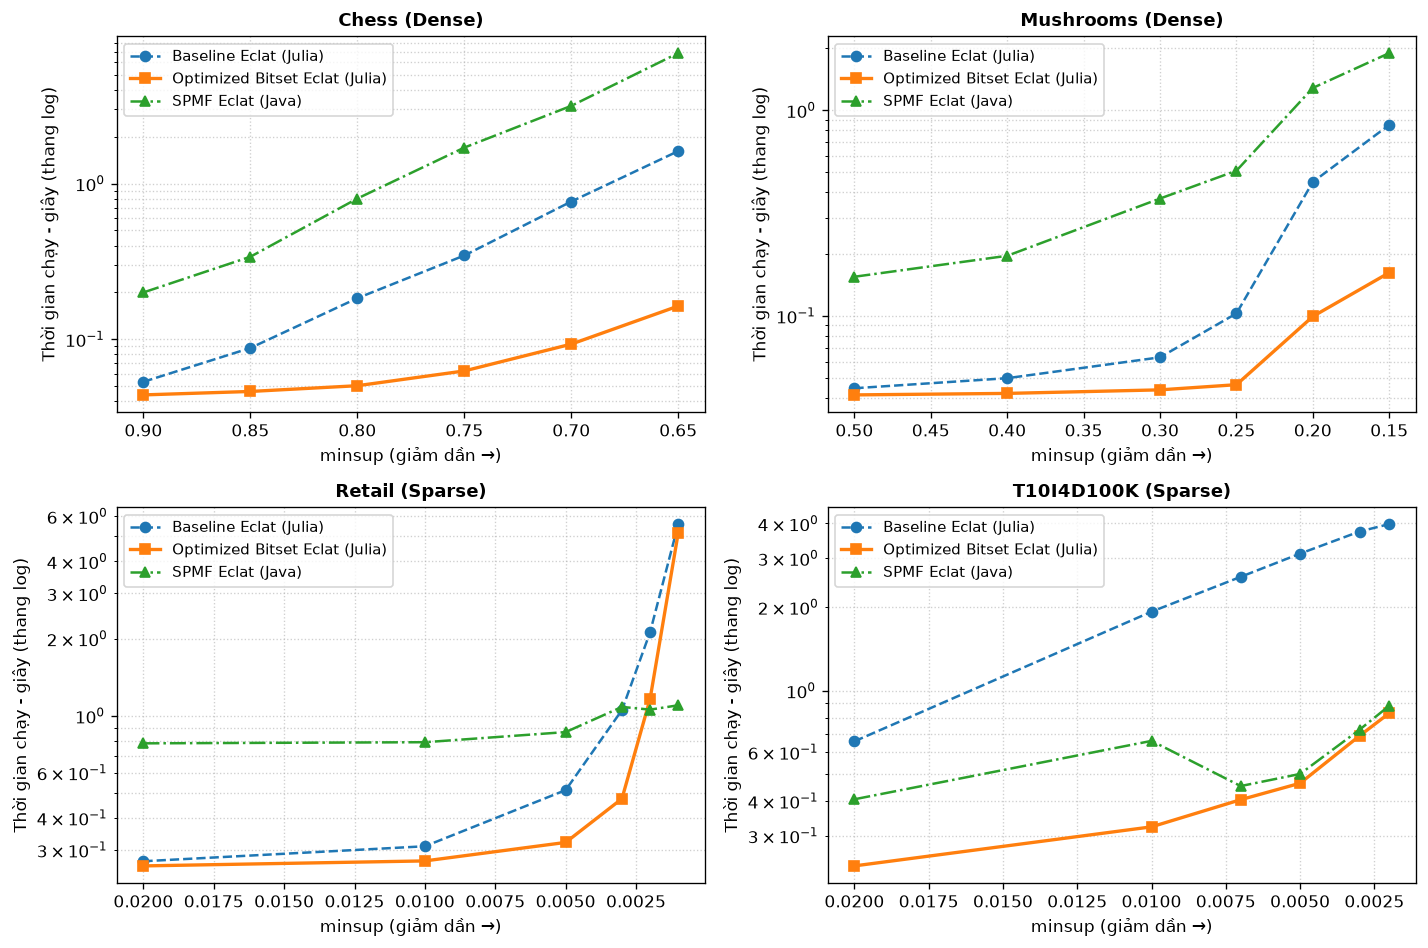

In [6]:
datasets = ["chess.txt", "mushrooms.txt", "retail.txt", "T10I4D100K.txt"]
titles   = ["Chess (Dense)", "Mushrooms (Dense)", "Retail (Sparse)", "T10I4D100K (Sparse)"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, ds, title in zip(axes, datasets, titles):
    sub_base = df_main[(df_main["dataset"] == ds) & (df_main["implementation"] == "baseline")]
    sub_opt  = df_main[(df_main["dataset"] == ds) & (df_main["implementation"] == "optimized")]

    ax.plot(sub_base["minsup"], sub_base["total_seconds"], marker="o", linestyle="--", label="Baseline Eclat (Julia)")
    ax.plot(sub_opt["minsup"],  sub_opt["total_seconds"],  marker="s", linewidth=2,    label="Optimized Bitset Eclat (Julia)")
    ax.plot(sub_opt["minsup"],  sub_opt["spmf_seconds"],   marker="^", linestyle="-.", label="SPMF Eclat (Java)")

    ax.invert_xaxis()  # Hiển thị minsup giảm dần từ trái sang phải
    ax.set_yscale("log")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("minsup (giảm dần →)")
    ax.set_ylabel("Thời gian chạy - giây (thang log)")
    ax.grid(True, which="both", linestyle=":", alpha=0.6)
    ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "exp2_runtime_vs_minsup.png"), bbox_inches="tight")
plt.show()

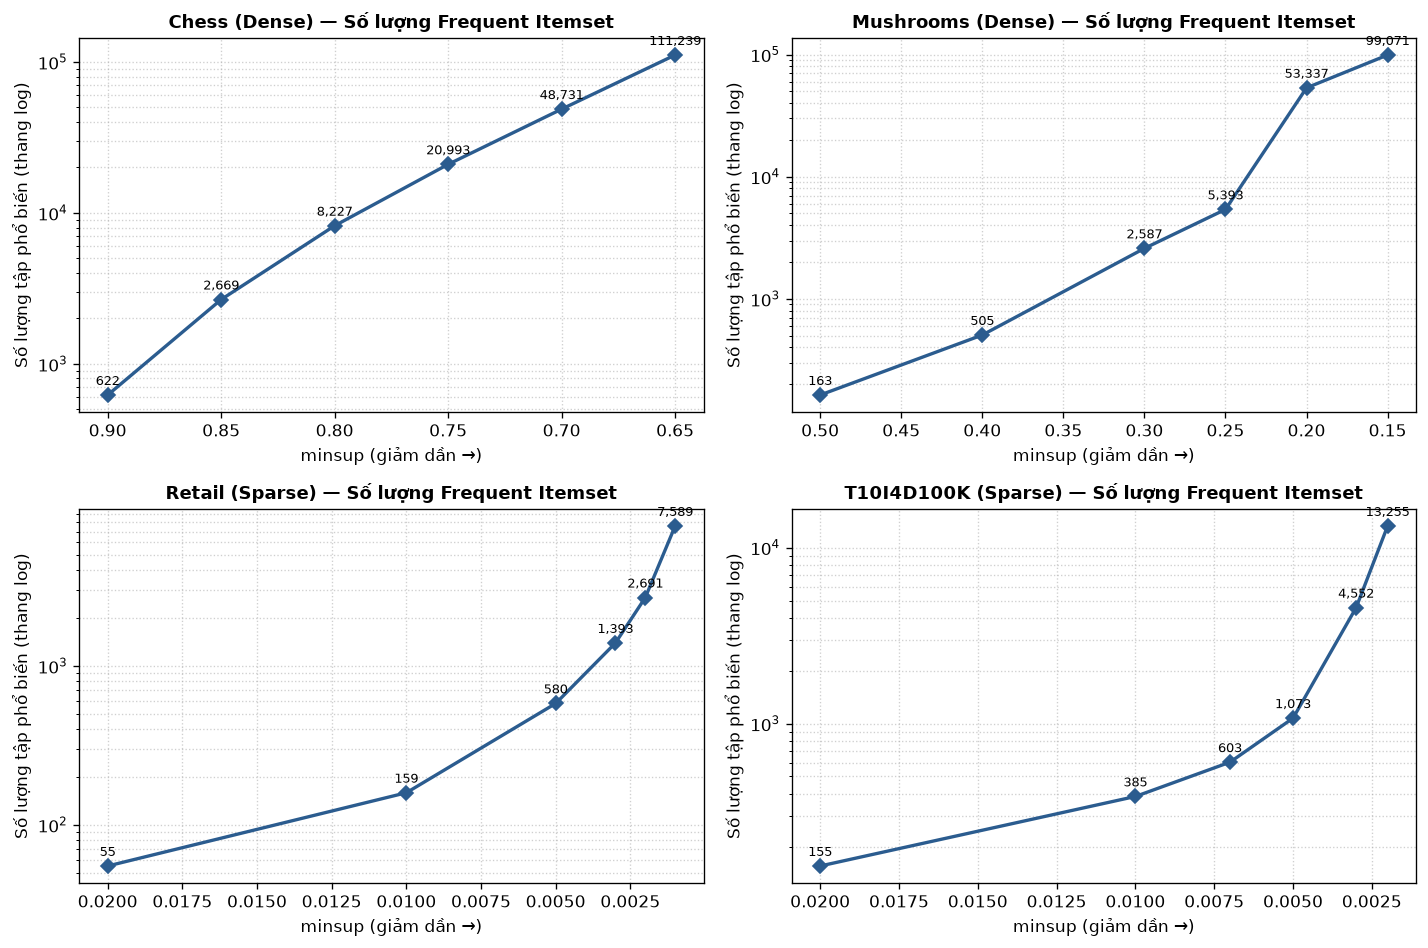

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, ds, title in zip(axes, datasets, titles):
    sub_opt = df_main[(df_main["dataset"] == ds) & (df_main["implementation"] == "optimized")]

    ax.plot(sub_opt["minsup"], sub_opt["n_itemsets"], marker="D", color="#2b5c8f", linewidth=2)
    for x, y in zip(sub_opt["minsup"], sub_opt["n_itemsets"]):
        ax.annotate(f"{y:,}", (x, y), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)

    ax.invert_xaxis()
    ax.set_yscale("log")
    ax.set_title(f"{title} — Số lượng Frequent Itemset", fontweight="bold")
    ax.set_xlabel("minsup (giảm dần →)")
    ax.set_ylabel("Số lượng tập phổ biến (thang log)")
    ax.grid(True, which="both", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "exp3_itemsets_vs_minsup.png"), bbox_inches="tight")
plt.show()

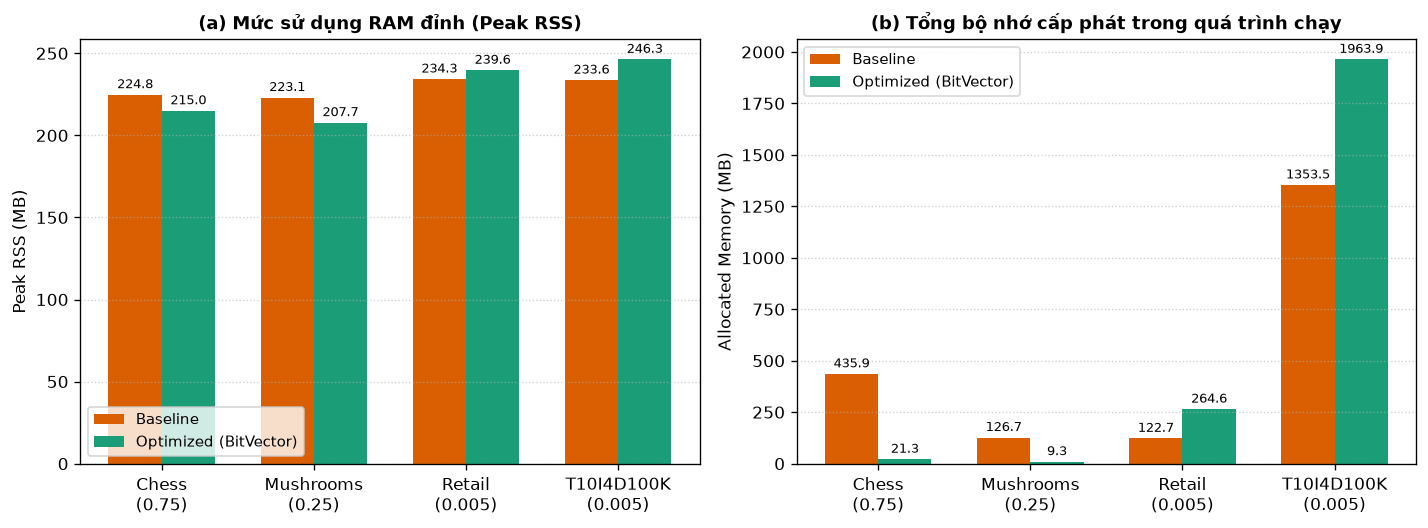

In [8]:
# Lọc dữ liệu alloc_mb tại đúng các mốc minsup trung bình trong exp4_memory.csv
med_merge = pd.merge(df_mem, df_main, on=["implementation", "dataset", "minsup"])

ds_labels = ["Chess\n(0.75)", "Mushrooms\n(0.25)", "Retail\n(0.005)", "T10I4D100K\n(0.005)"]
x = np.arange(len(datasets))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Biểu đồ 4a: Peak RSS (MB)
rss_base = [med_merge[(med_merge["dataset"] == d) & (med_merge["implementation"] == "baseline")]["peak_rss_mb"].values[0] for d in datasets]
rss_opt  = [med_merge[(med_merge["dataset"] == d) & (med_merge["implementation"] == "optimized")]["peak_rss_mb"].values[0] for d in datasets]

b1 = ax1.bar(x - width/2, rss_base, width, label="Baseline", color="#d95f02")
b2 = ax1.bar(x + width/2, rss_opt,  width, label="Optimized (BitVector)", color="#1b9e77")
ax1.set_xticks(x)
ax1.set_xticklabels(ds_labels)
ax1.set_ylabel("Peak RSS (MB)")
ax1.set_title("(a) Mức sử dụng RAM đỉnh (Peak RSS)", fontweight="bold")
ax1.grid(axis="y", linestyle=":", alpha=0.6)
ax1.legend()
ax1.bar_label(b1, fmt="%.1f", fontsize=8, padding=2)
ax1.bar_label(b2, fmt="%.1f", fontsize=8, padding=2)

# Biểu đồ 4b: Tổng bộ nhớ cấp phát (Allocated MB)
alloc_base = [med_merge[(med_merge["dataset"] == d) & (med_merge["implementation"] == "baseline")]["alloc_mb"].values[0] for d in datasets]
alloc_opt  = [med_merge[(med_merge["dataset"] == d) & (med_merge["implementation"] == "optimized")]["alloc_mb"].values[0] for d in datasets]

b3 = ax2.bar(x - width/2, alloc_base, width, label="Baseline", color="#d95f02")
b4 = ax2.bar(x + width/2, alloc_opt,  width, label="Optimized (BitVector)", color="#1b9e77")
ax2.set_xticks(x)
ax2.set_xticklabels(ds_labels)
ax2.set_ylabel("Allocated Memory (MB)")
ax2.set_title("(b) Tổng bộ nhớ cấp phát trong quá trình chạy", fontweight="bold")
ax2.grid(axis="y", linestyle=":", alpha=0.6)
ax2.legend()
ax2.bar_label(b3, fmt="%.1f", fontsize=8, padding=2)
ax2.bar_label(b4, fmt="%.1f", fontsize=8, padding=2)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "exp4_memory_comparison.png"), bbox_inches="tight")
plt.show()

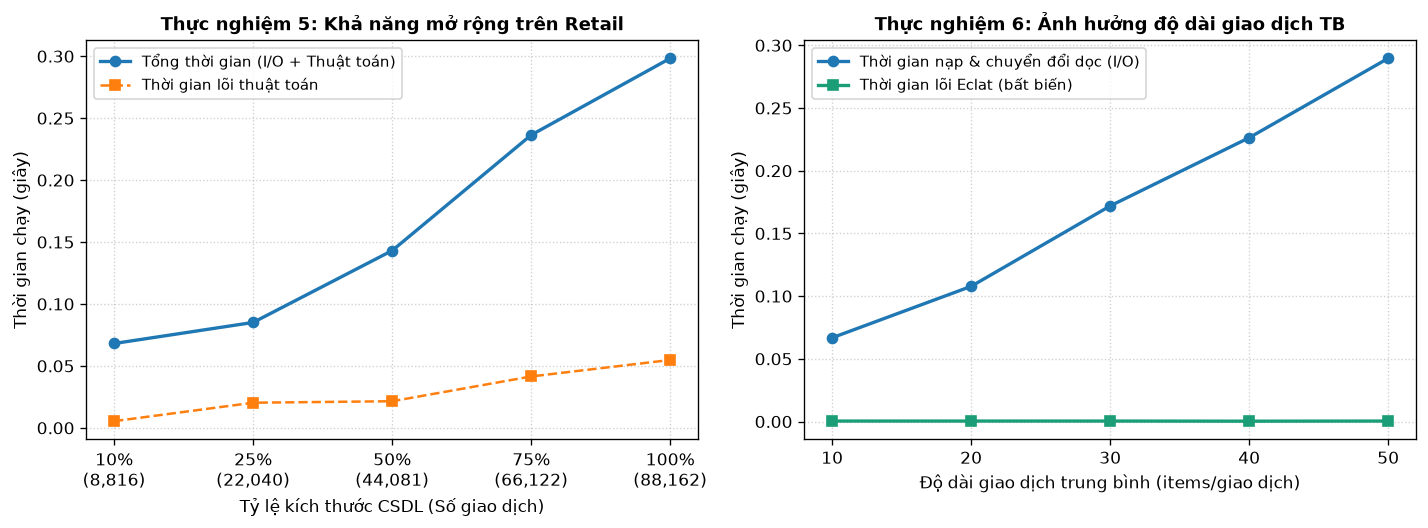

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Biểu đồ 5: Scalability trên Retail (10% -> 100%)
pct_labels = [f"{int(f*100)}%\n({n:,})" for f, n in zip(df_scale["fraction"], df_scale["num_tx"])]
ax1.plot(pct_labels, df_scale["total_seconds"], marker="o", linewidth=2, label="Tổng thời gian (I/O + Thuật toán)")
ax1.plot(pct_labels, df_scale["algo_seconds"],  marker="s", linestyle="--", label="Thời gian lõi thuật toán")
ax1.set_title("Thực nghiệm 5: Khả năng mở rộng trên Retail", fontweight="bold")
ax1.set_xlabel("Tỷ lệ kích thước CSDL (Số giao dịch)")
ax1.set_ylabel("Thời gian chạy (giây)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Biểu đồ 6: Ảnh hưởng của độ dài giao dịch trung bình
ax2.plot(df_txlen["avg_tx_length"], df_txlen["load_seconds"], marker="o", linewidth=2, label="Thời gian nạp & chuyển đổi dọc (I/O)")
ax2.plot(df_txlen["avg_tx_length"], df_txlen["algo_seconds"], marker="s", linewidth=2, color="#1b9e77", label="Thời gian lõi Eclat (bất biến)")
ax2.set_title("Thực nghiệm 6: Ảnh hưởng độ dài giao dịch TB", fontweight="bold")
ax2.set_xlabel("Độ dài giao dịch trung bình (items/giao dịch)")
ax2.set_ylabel("Thời gian chạy (giây)")
ax2.set_xticks(df_txlen["avg_tx_length"])
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "exp5_6_scalability_and_txlen.png"), bbox_inches="tight")
plt.show()

---
## CHƯƠNG 3: ỨNG DỤNG THỰC TIỄN CỦA THUẬT TOÁN OPTIMIZED BITSET ECLAT

Sau khi kiểm chứng tính đúng đắn và hiệu năng vượt trội của **Optimized Bitset Eclat** ở Chương 2, chương này trình bày kết quả triển khai thuật toán trên hai bài toán thực tế đại diện cho hai đặc trưng dữ liệu đối lập:
1. **Ứng dụng 1 — Phân tích giỏ hàng (Market Basket Analysis)** trên tập `Groceries_dataset.csv` *(dữ liệu giao dịch thưa - Sparse)*.
2. **Ứng dụng 2 — Khai thác mẫu trình tự gen Splice-Junction (DNA)** trên tập `dna.csv` *(dữ liệu thuộc tính vị trí dày đặc - Dense)*.

In [10]:
# Chạy lại hai ứng dụng bằng Julia (ghi kết quả vào results/app1 và results/app2).
# Các ô biểu đồ bên dưới đọc các CSV này; nếu chạy lỗi, CSV đã commit trong repo vẫn dùng được.
jl("demo.jl", "--app", "app1")
jl("demo.jl", "--app", "app2")

  CHƯƠNG TRÌNH TRÌNH DIỄN ĐỒ ÁN KHAI PHÁ DỮ LIỆU (GROUP_08) — THUẬT TOÁN ECLAT
  Thời gian chạy: 2026-11-26 15:32:37 | Chế độ: APP1

=== ỨNG DỤNG 1: PHÂN TÍCH GIỎ HÀNG (MARKET BASKET ANALYSIS) ===
• Dữ liệu đầu vào : D:\Group_08\data/apps/Groceries_dataset.csv
• Tổng giao dịch  : 14963 | Số mặt hàng phân biệt: 167
• Frequent Itemsets tìm được (minsup=0.002): 330 (trong 0.2103s)
• Luật kết hợp thỏa mãn (minconf=0.07, Lift >= 1.0): 15 (trong 0.0003s)

TOP-10 LUẬT KẾT HỢP CÓ CHỈ SỐ LIFT CAO NHẤT:
---------------------------------------------------------------------------------------------------------
Top  | Antecedent (X)                     => Consequent (Y)           | Support | Conf.   | Lift  
---------------------------------------------------------------------------------------------------------
1    | {curd}                             => {sausage}                | 0.0029  | 0.0873  | 1.4466
2    | {frozen vegetables}                => {sausage}                | 0.0021  | 0.0740  |

In [11]:
import glob

# Tự động quét toàn bộ file CSV kết quả trong thư mục results/ (loại trừ thư mục benchmark)
base_results = os.path.abspath(os.path.join(RESULTS_DIR, ".."))
all_csvs = [
    f for f in glob.glob(os.path.join(base_results, "**", "*.csv"), recursive=True)
    if "benchmark" not in os.path.relpath(f, base_results).lower()
]

print(f"Tìm thấy {len(all_csvs)} file kết quả cho Chương 3 trong '{base_results}':")
for f in sorted(all_csvs):
    print(" -", os.path.relpath(f, base_results))

def load_app_csv(keywords, fallback_idx=None):
    """Tự động tìm và đọc file CSV theo từ khóa tên file."""
    for f in sorted(all_csvs):
        name = os.path.basename(f).lower()
        if all(k.lower() in name for k in keywords):
            return pd.read_csv(f), os.path.basename(f)
    if fallback_idx is not None and fallback_idx < len(all_csvs):
        f = sorted(all_csvs)[fallback_idx]
        return pd.read_csv(f), os.path.basename(f)
    return None, None

Tìm thấy 5 file kết quả cho Chương 3 trong 'D:\Group_08\results':
 - app1\app1_all_rules.csv
 - app1\app1_top10_rules.csv
 - app2\app2_dna_EI_Donor_patterns.csv
 - app2\app2_dna_IE_Acceptor_patterns.csv
 - app2\app2_dna_N_Neither_patterns.csv


### 3.1. Ứng dụng 1: Phân tích giỏ hàng (Market Basket Analysis) trên `Groceries_dataset.csv`

Mục tiêu của bài toán là trích xuất các tập mặt hàng phổ biến (*Frequent Itemsets*) và các luật kết hợp (*Association Rules*) có độ tin cậy cao nhằm phục vụ chiến lược gợi ý sản phẩm (Cross-selling) và bố trí quầy kệ siêu thị.

Tổng số luật trích xuất (app1_all_rules.csv): 15 luật


,rank,antecedent,consequent,support_count,support,confidence,lift
0,1,curd,sausage,44,0.002941,0.087302,1.4466
1,2,frozen vegetables,sausage,31,0.002072,0.073986,1.2260
2,3,bottled beer,sausage,50,0.003342,0.073746,1.2220
3,4,frankfurter,other vegetables,77,0.005146,0.136283,1.1161
4,5,sausage,yogurt,86,0.005748,0.095238,1.1090
5,6,frozen vegetables,root vegetables,32,0.002139,0.076372,1.0978
6,7,chocolate,rolls/buns,42,0.002807,0.118980,1.0816
7,8,frozen meals,other vegetables,32,0.002139,0.127490,1.0441
8,9,meat,other vegetables,32,0.002139,0.126984,1.0400
9,10,sausage,soda,89,0.005948,0.098560,1.0150


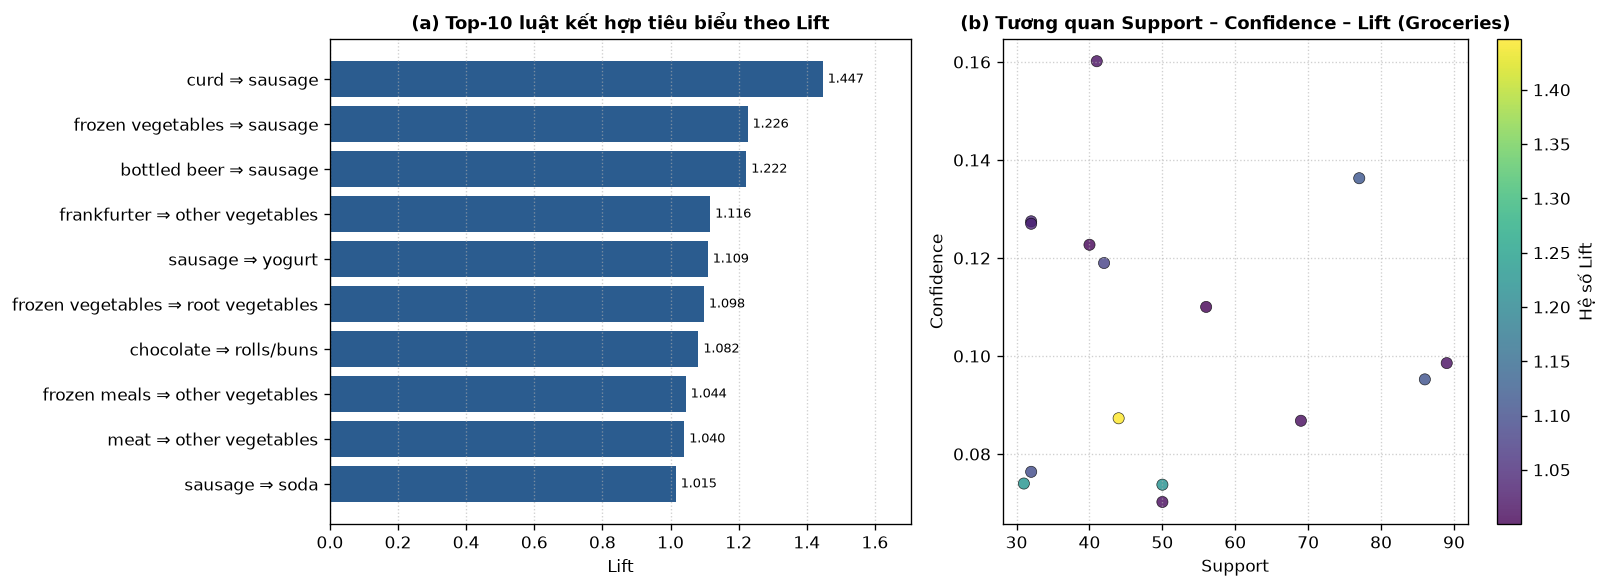

In [12]:
# Nạp dữ liệu kết quả Ứng dụng 1 từ thư mục app1/
df_groc_all, f_g_all     = load_app_csv(["app1", "all_rules"])
df_groc_top10, f_g_top10 = load_app_csv(["app1", "top10"])

# Fallback nếu chỉ có 1 trong 2 file
if df_groc_all is None:
    df_groc_all, f_g_all = load_app_csv(["app1"])
if df_groc_top10 is None and df_groc_all is not None:
    df_groc_top10 = df_groc_all.copy()

def prepare_rules_df(df):
    """Chuẩn hóa tên cột và tạo nhãn hiển thị cho luật kết hợp."""
    df = df.copy()
    cols_lower = {c.lower(): c for c in df.columns}
    
    sup_col  = next((cols_lower[k] for k in cols_lower if "sup" in k), None)
    conf_col = next((cols_lower[k] for k in cols_lower if "conf" in k), None)
    lift_col = next((cols_lower[k] for k in cols_lower if "lift" in k), None)
    
    # Tạo cột nhãn luật (A => B)
    if "rule" in cols_lower:
        df["_rule_label"] = df[cols_lower["rule"]].astype(str)
    elif "antecedent" in cols_lower and "consequent" in cols_lower:
        df["_rule_label"] = (
            df[cols_lower["antecedent"]].astype(str) + " ⇒ " + df[cols_lower["consequent"]].astype(str)
        )
    elif "lhs" in cols_lower and "rhs" in cols_lower:
        df["_rule_label"] = (
            df[cols_lower["lhs"]].astype(str) + " ⇒ " + df[cols_lower["rhs"]].astype(str)
        )
    else:
        df["_rule_label"] = df.iloc[:, 0].astype(str)
        
    return df, sup_col, conf_col, lift_col

if df_groc_all is not None:
    df_groc_all, sup_col, conf_col, lift_col = prepare_rules_df(df_groc_all)
    df_groc_top10, _, _, _ = prepare_rules_df(df_groc_top10)
    
    rank_col = lift_col or conf_col or sup_col
    top10_plot = df_groc_top10.sort_values(by=rank_col, ascending=False).head(10)
    
    print(f"Tổng số luật trích xuất ({f_g_all}): {len(df_groc_all):,} luật")
    display(top10_plot.drop(columns=["_rule_label"]))

    # Trực quan hóa kết quả Ứng dụng 1
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5))

    # Biểu đồ (a): Top-10 luật kết hợp nổi bật nhất
    top10_rev = top10_plot.iloc[::-1]
    bars = ax1.barh(top10_rev["_rule_label"], top10_rev[rank_col], color="#2b5c8f")
    ax1.set_title(f"(a) Top-10 luật kết hợp tiêu biểu theo {rank_col.capitalize()}", fontweight="bold")
    ax1.set_xlabel(rank_col.capitalize())
    ax1.grid(axis="x", linestyle=":", alpha=0.6)
    ax1.bar_label(bars, fmt="%.3f", fontsize=8, padding=3)
    ax1.set_xlim(0, top10_rev[rank_col].max() * 1.18)

    # Biểu đồ (b): Phân bố Support - Confidence - Lift trên toàn bộ tập luật
    if sup_col and conf_col:
        c_val = df_groc_all[lift_col] if lift_col else df_groc_all[conf_col]
        sc = ax2.scatter(
            df_groc_all[sup_col],
            df_groc_all[conf_col],
            c=c_val,
            cmap="viridis",
            alpha=0.8,
            edgecolors="k",
            linewidths=0.4,
            s=45
        )
        cbar = plt.colorbar(sc, ax=ax2)
        cbar.set_label(f"Hệ số {lift_col.capitalize()}" if lift_col else conf_col.capitalize())
        ax2.set_title("(b) Tương quan Support – Confidence – Lift (Groceries)", fontweight="bold")
        ax2.set_xlabel("Support")
        ax2.set_ylabel("Confidence")
        ax2.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "app1_groceries_analysis.png"), bbox_inches="tight")
    plt.show()
else:
    print("Không tìm thấy file kết quả trong thư mục app1/.")

### 3.2. Ứng dụng 2: Khai thác mẫu trình tự gen Splice-Junction (DNA) trên `dna.csv`

Tập dữ liệu **Splice-Junction Gene Sequences (DNA)** mô tả 60 vị trí nucleotide (`A`, `C`, `G`, `T`) xung quanh ranh giới nối gen được phân thành 3 lớp:
* **`EI` (Exon–Intron):** Ranh giới *Donor* (thường bảo thủ cặp `GT` ngay đầu vùng Intron).
* **`IE` (Intron–Exon):** Ranh giới *Acceptor* (thường bảo thủ cặp `AG` ngay cuối vùng Intron).
* **`N` (Neither):** Trình tự không chứa điểm nối gen.

Nhờ biểu diễn dọc **BitVector**, thuật toán Optimized Bitset Eclat xử lý hiệu quả phép giao tidset trên không gian tổ hợp vị trí nucleotide có mật độ cao.

Tổng số mẫu trích xuất trên toàn bộ tập DNA: 88 mẫu
 - EI_Donor   : 44 mẫu
 - IE_Acceptor: 44 mẫu
 - N_Neither  : 0 mẫu


,class,rank,length,pattern,support_count,support_rel
0,EI_Donor,1,2,"{Pos31=G, Pos32=T}",759,0.989570
1,EI_Donor,2,2,"{Pos31=G, Pos35=G}",657,0.856584
2,EI_Donor,3,3,"{Pos31=G, Pos32=T, Pos35=G}",652,0.850065
3,EI_Donor,4,2,"{Pos32=T, Pos35=G}",652,0.850065
4,EI_Donor,5,2,"{Pos30=G, Pos31=G}",626,0.816167
5,IE_Acceptor,1,2,"{Pos29=A, Pos30=G}",761,0.994771
6,IE_Acceptor,2,2,"{Pos28=C, Pos30=G}",604,0.789542
7,IE_Acceptor,3,3,"{Pos28=C, Pos29=A, Pos30=G}",603,0.788235
8,IE_Acceptor,4,2,"{Pos28=C, Pos29=A}",603,0.788235
9,IE_Acceptor,5,3,"{Pos29=A, Pos30=G, Pos31=G}",362,0.473203


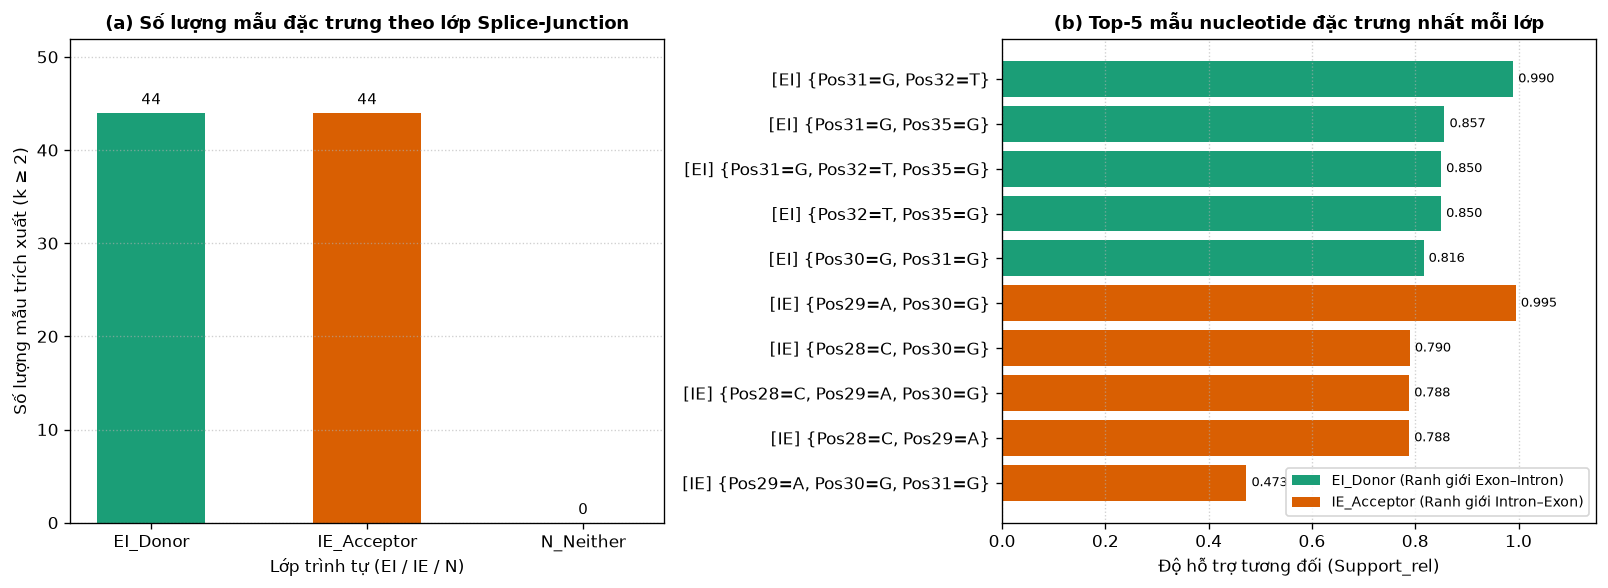

In [13]:
from matplotlib.patches import Patch

# Nạp đầy đủ cả 3 file kết quả của Ứng dụng 2 (DNA Splice-Junction)
df_dna_ei, _ = load_app_csv(["app2", "ei_donor"])
df_dna_ie, _ = load_app_csv(["app2", "ie_acceptor"])
df_dna_n,  _ = load_app_csv(["app2", "n_neither"])

dna_parts = [df for df in [df_dna_ei, df_dna_ie, df_dna_n] if df is not None]

if dna_parts:
    df_dna_all = pd.concat(dna_parts, ignore_index=True)
    print(f"Tổng số mẫu trích xuất trên toàn bộ tập DNA: {len(df_dna_all)} mẫu")
    print(f" - EI_Donor   : {len(df_dna_ei) if df_dna_ei is not None else 0} mẫu")
    print(f" - IE_Acceptor: {len(df_dna_ie) if df_dna_ie is not None else 0} mẫu")
    print(f" - N_Neither  : {len(df_dna_n)  if df_dna_n  is not None else 0} mẫu")

    # Hiển thị Top-5 mẫu đặc trưng nhất của EI_Donor và IE_Acceptor
    display(
        pd.concat([
            df_dna_ei.sort_values(by="support_rel", ascending=False).head(5),
            df_dna_ie.sort_values(by="support_rel", ascending=False).head(5)
        ], ignore_index=True)
    )

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5))

    # Biểu đồ (a): Số lượng mẫu phổ biến trích xuất được ở cả 3 lớp
    classes = ["EI_Donor", "IE_Acceptor", "N_Neither"]
    counts  = [
        len(df_dna_ei) if df_dna_ei is not None else 0,
        len(df_dna_ie) if df_dna_ie is not None else 0,
        len(df_dna_n)  if df_dna_n  is not None else 0,
    ]
    colors_dna = ["#1b9e77", "#d95f02", "#2b5c8f"]

    b1 = ax1.bar(classes, counts, color=colors_dna, width=0.5)
    ax1.set_title("(a) Số lượng mẫu đặc trưng theo lớp Splice-Junction", fontweight="bold")
    ax1.set_xlabel("Lớp trình tự (EI / IE / N)")
    ax1.set_ylabel("Số lượng mẫu trích xuất (k ≥ 2)")
    ax1.grid(axis="y", linestyle=":", alpha=0.6)
    ax1.bar_label(b1, fmt="%d", fontsize=9, padding=3)
    ax1.set_ylim(0, max(counts) * 1.18)

    # Biểu đồ (b): Top-5 tổ hợp vị trí nucleotide đặc trưng nhất mỗi lớp
    top_ei = df_dna_ei.sort_values(by="support_rel", ascending=False).head(5)
    top_ie = df_dna_ie.sort_values(by="support_rel", ascending=False).head(5)
    top_combined = pd.concat([top_ei, top_ie], ignore_index=True).iloc[::-1]

    bar_colors = ["#1b9e77" if c == "EI_Donor" else "#d95f02" for c in top_combined["class"]]
    labels_b   = [f"[{c.split('_')[0]}] {p}" for c, p in zip(top_combined["class"], top_combined["pattern"])]

    b2 = ax2.barh(labels_b, top_combined["support_rel"], color=bar_colors)
    ax2.set_title("(b) Top-5 mẫu nucleotide đặc trưng nhất mỗi lớp", fontweight="bold")
    ax2.set_xlabel("Độ hỗ trợ tương đối (Support_rel)")
    ax2.grid(axis="x", linestyle=":", alpha=0.6)
    ax2.bar_label(b2, fmt="%.3f", fontsize=8, padding=3)
    ax2.set_xlim(0, 1.15)

    legend_handles = [
        Patch(facecolor="#1b9e77", label="EI_Donor (Ranh giới Exon–Intron)"),
        Patch(facecolor="#d95f02", label="IE_Acceptor (Ranh giới Intron–Exon)")
    ]
    ax2.legend(handles=legend_handles, loc="lower right", fontsize=8.5)

    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "app2_dna_splice_junction.png"), bbox_inches="tight")
    plt.show()
else:
    print("Không tìm thấy file kết quả trong thư mục app2/.")